# 13 — Proof-of-Concept Story and Visual Summary

## Heat-conditioned accessibility in Sevilla

This notebook is a **reporting and synthesis notebook**. It does not replace the analytical notebooks that created the results. Instead, it brings the main outputs together into one reproducible visual story.

The proof-of-concept asks whether thermal stress can be incorporated directly into pedestrian impedance and accessibility analysis:

\[
\text{urban form}
\rightarrow
\text{thermal environment}
\rightarrow
\text{thermal network impedance}
\rightarrow
\text{accessibility loss}
\rightarrow
\text{observed mobility response}
\]

> **Scope.** The current thermal model covers a limited proof-of-concept area within Sevilla. Results should therefore be interpreted as evidence that the method works, not as citywide estimates for Sevilla.

## 0. Setup

This notebook reads saved outputs from the repository wherever possible. Missing optional files are reported rather than silently replaced.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import networkx as nx
import osmnx as ox
import rasterio
from rasterio.plot import show as rioshow

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

RAW = PROJECT_ROOT / "data" / "raw"
INTERIM = PROJECT_ROOT / "data" / "interim"
PROCESSED = PROJECT_ROOT / "data" / "processed"
ACCESS_DIR = PROJECT_ROOT / "outputs" / "accessibility"
SOLWEIG_DIR = PROJECT_ROOT / "outputs" / "solweig" / "summary"
MOBILE_INTERIM = PROJECT_ROOT / "data" / "mobile" / "interim"
MOBILE_PROCESSED = PROJECT_ROOT / "data" / "mobile" / "processed"
FIGURES = PROJECT_ROOT / "outputs" / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def exists(path):
    path = Path(path)
    ok = path.exists()
    print(("✓" if ok else "—"), path.relative_to(PROJECT_ROOT) if ok or path.is_absolute() else path)
    return ok

## 1. Research workflow

The figure below shows the **scientific logic** rather than every preprocessing task in the repository. The mobile-phone analysis is kept as an observational layer that can eventually be compared with the modeled accessibility response.

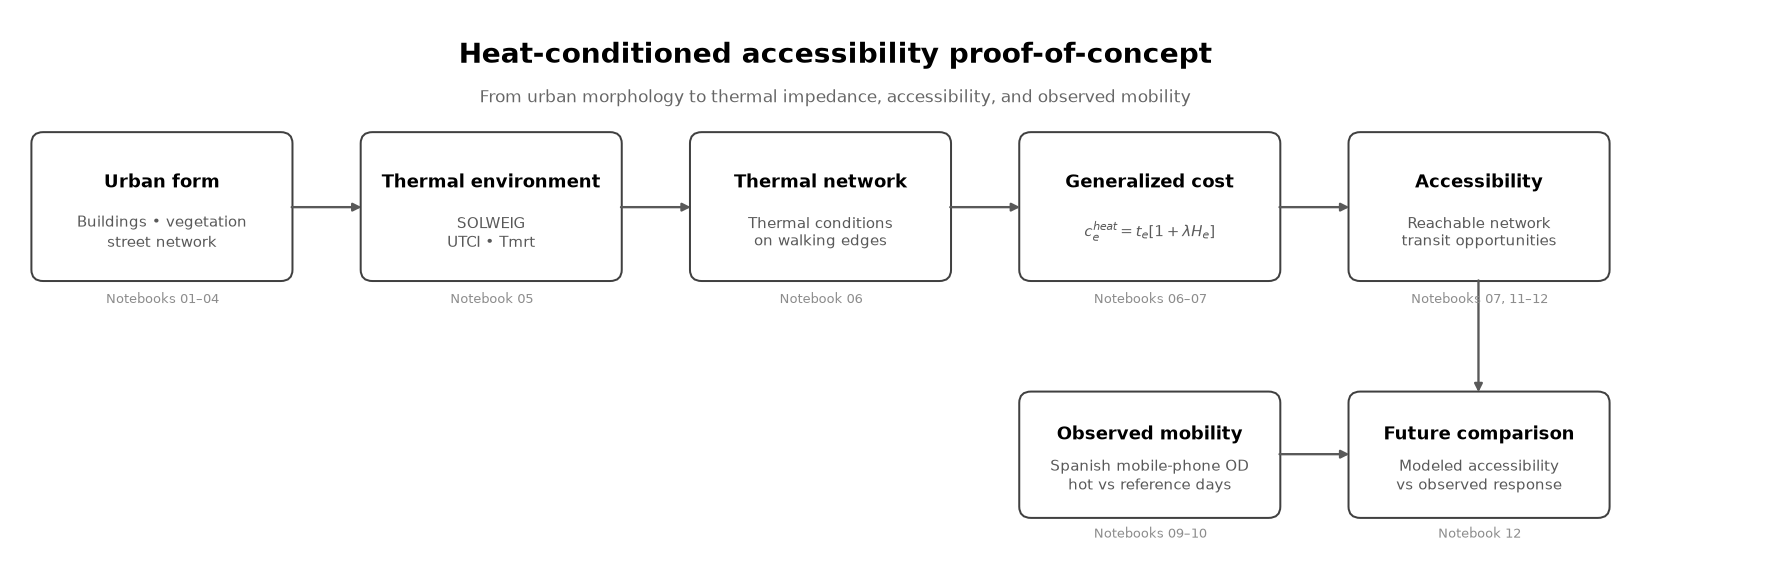

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/figures/13_workflow_overview.png


In [2]:
fig, ax = plt.subplots(figsize=(15, 5.0))
ax.set_xlim(0, 15)
ax.set_ylim(0, 5)
ax.axis("off")

def box(x, y, w, h, title, subtitle):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.035,rounding_size=0.10",
        linewidth=1.2,
        facecolor="white",
        edgecolor="0.25",
    )
    ax.add_patch(patch)
    ax.text(x+w/2, y+h*0.67, title, ha="center", va="center",
            fontsize=11, fontweight="bold")
    ax.text(x+w/2, y+h*0.32, subtitle, ha="center", va="center",
            fontsize=9, color="0.35", linespacing=1.25)

def arrow(x1, y1, x2, y2):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="-|>", lw=1.4, color="0.35")
    )

y, w, h = 2.65, 2.15, 1.25

box(0.20,  y, w, h, "Urban form", "Buildings • vegetation\nstreet network")
box(3.00,  y, w, h, "Thermal environment", "SOLWEIG\nUTCI • Tmrt")
box(5.80,  y, w, h, "Thermal network", "Thermal conditions\non walking edges")
box(8.60,  y, w, h, "Generalized cost", r"$c_e^{heat}=t_e[1+\lambda H_e]$")
box(11.40, y, w, h, "Accessibility", "Reachable network\ntransit opportunities")

for x1, x2 in [(2.35,3.00),(5.15,5.80),(7.95,8.60),(10.75,11.40)]:
    arrow(x1, 3.27, x2, 3.27)

box(8.60, 0.55, w, 1.05, "Observed mobility",
    "Spanish mobile-phone OD\nhot vs reference days")
box(11.40, 0.55, w, 1.05, "Future comparison",
    "Modeled accessibility\nvs observed response")
arrow(10.75, 1.08, 11.40, 1.08)
arrow(12.47, 2.65, 12.47, 1.60)

ax.text(7.0, 4.55, "Heat-conditioned accessibility proof-of-concept",
        ha="center", fontsize=17, fontweight="bold")
ax.text(7.0, 4.20,
        "From urban morphology to thermal impedance, accessibility, and observed mobility",
        ha="center", fontsize=10, color="0.4")

stage_labels = [
    (1.28, "01–04"), (4.08, "05"), (6.88, "06"),
    (9.68, "06–07"), (12.48, "07, 11–12"),
    (9.68, "09–10"), (12.48, "12")
]
for x, lab in stage_labels:
    yy = 2.43 if x < 13 and x not in (9.68,12.48) else None

ax.text(1.28, 2.42, "Notebooks 01–04", ha="center", fontsize=8, color="0.55")
ax.text(4.08, 2.42, "Notebook 05", ha="center", fontsize=8, color="0.55")
ax.text(6.88, 2.42, "Notebook 06", ha="center", fontsize=8, color="0.55")
ax.text(9.68, 2.42, "Notebooks 06–07", ha="center", fontsize=8, color="0.55")
ax.text(12.48, 2.42, "Notebooks 07, 11–12", ha="center", fontsize=8, color="0.55")
ax.text(9.68, 0.34, "Notebooks 09–10", ha="center", fontsize=8, color="0.55")
ax.text(12.48, 0.34, "Notebook 12", ha="center", fontsize=8, color="0.55")

plt.tight_layout()
workflow_path = FIGURES / "13_workflow_overview.png"
plt.savefig(workflow_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", workflow_path)

## 2. Methodological idea

Conventional accessibility uses travel cost \(c_{ij}\) to connect an origin \(i\) to opportunities \(j\):

\[
A_i = \sum_j O_j f(c_{ij})
\]

The proof-of-concept replaces conventional walking time with a thermally adjusted edge cost:

\[
c_e^{heat}
=
t_e\left[1+\lambda\max(UTCI_e-32,0)\right]
\]

where:

- \(t_e\) is conventional walking time on edge \(e\);
- \(UTCI_e\) is modeled thermal stress on the edge;
- \(32^\circ C\) is the selected heat-stress threshold;
- \(\lambda\) is a **sensitivity parameter**, not a behaviorally calibrated coefficient.

The methodological contribution is therefore not simply to map heat exposure, but to ask how environmental conditions alter the **impedance used to calculate accessibility**.

## 3. Stage A — Study area and urban-form inputs

The thermal proof-of-concept uses a limited area of Sevilla. Urban-form information was assembled from the street network, buildings, vegetation, and enriched building-height data before preparing SOLWEIG inputs.

The visual below combines the walking network, building footprints, and mapped tree features when those files are available.

{'buildings': True, 'trees': True, 'graph': True, 'utci': True}


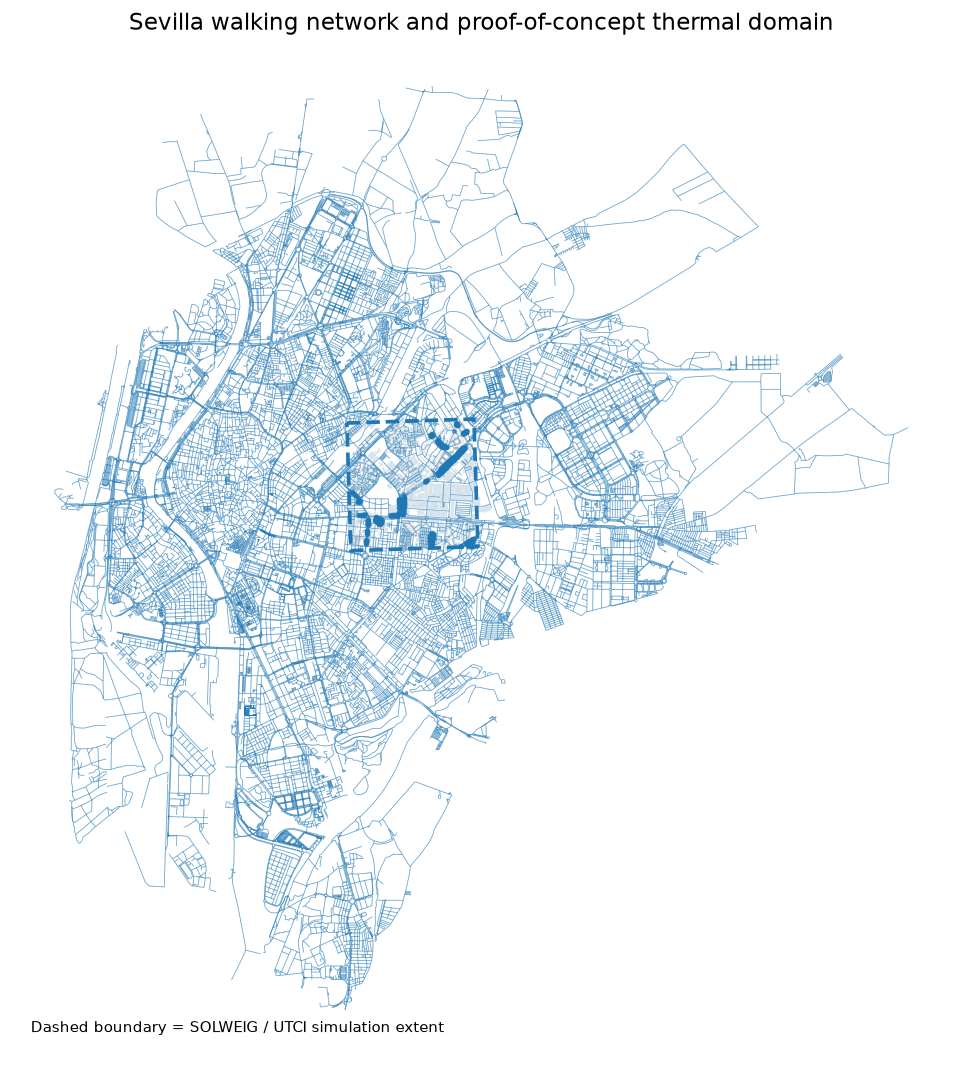

In [15]:
UTCI_RASTER = PROJECT_ROOT / "outputs" / "solweig" / "summary" / "utci_max.tif"
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import rasterio

from shapely.geometry import box


building_path = INTERIM / "sevilla_buildings_voxcity.gpkg"
tree_path = INTERIM / "sevilla_trees_voxcity.gpkg"
graph_path = RAW / "sevilla_walk.graphml"

utci_path = (
    PROJECT_ROOT
    / "outputs"
    / "solweig"
    / "summary"
    / "utci_max.tif"
)

available = {
    "buildings": building_path.exists(),
    "trees": tree_path.exists(),
    "graph": graph_path.exists(),
    "utci": utci_path.exists(),
}

print(available)


if available["graph"]:

    # --------------------------------------------------
    # Walking network
    # --------------------------------------------------

    G0 = ox.load_graphml(graph_path)

    nodes0, edges0 = ox.graph_to_gdfs(G0)

    target_crs = edges0.crs


    # --------------------------------------------------
    # Figure
    # --------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(9, 9)
    )

    edges0.plot(
        ax=ax,
        linewidth=0.45,
        alpha=0.40
    )


    # --------------------------------------------------
    # Buildings
    # --------------------------------------------------

    if available["buildings"]:

        buildings = gpd.read_file(
            building_path
        ).to_crs(target_crs)

        buildings.plot(
            ax=ax,
            alpha=0.18,
            edgecolor="0.35",
            linewidth=0.15
        )


    # --------------------------------------------------
    # Trees
    # --------------------------------------------------

    if available["trees"]:

        trees = gpd.read_file(
            tree_path
        ).to_crs(target_crs)

        tree_pts = trees[
            trees.geometry.geom_type
            == "Point"
        ]

        if len(tree_pts):

            tree_pts.plot(
                ax=ax,
                markersize=5,
                alpha=0.50
            )


    # --------------------------------------------------
    # UTCI / SOLWEIG simulation footprint
    # --------------------------------------------------

    if available["utci"]:

        with rasterio.open(
            utci_path
        ) as src:

            raster_bounds = src.bounds
            raster_crs = src.crs

        utci_extent = gpd.GeoDataFrame(
            {
                "layer": [
                    "SOLWEIG / UTCI domain"
                ]
            },
            geometry=[
                box(
                    raster_bounds.left,
                    raster_bounds.bottom,
                    raster_bounds.right,
                    raster_bounds.top
                )
            ],
            crs=raster_crs
        )

        utci_extent = (
            utci_extent
            .to_crs(target_crs)
        )

        # Boundary only
        utci_extent.boundary.plot(
            ax=ax,
            linewidth=2.2,
            linestyle="--",
            zorder=10
        )


    # --------------------------------------------------
    # Figure labels
    # --------------------------------------------------

    ax.set_title(
        "Sevilla walking network and proof-of-concept thermal domain",
        fontsize=14
    )

    ax.text(
        0.02,
        0.02,
        "Dashed boundary = SOLWEIG / UTCI simulation extent",
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="bottom"
    )

    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

else:

    print(
        "Raw walking graph not found; "
        "study-area figure skipped."
    )

### Early interpretation

This stage establishes the **physical urban context** that eventually influences modeled thermal conditions. The current proof-of-concept does not cover all of Sevilla, so later accessibility results should not be interpreted as citywide impacts.

## 4. Stage B — Thermal simulation with SOLWEIG

The prepared urban-form rasters were used in SOLWEIG with a PVGIS EPW typical meteorological year. The current proof-of-concept uses a daily-maximum UTCI surface as a stress-test input.

Reported PoC thermal ranges were:

- mean Tmrt ≈ **38.5°C**;
- Tmrt range ≈ **10.6–72.2°C**;
- mean UTCI ≈ **28.2°C**;
- UTCI range ≈ **14.4–42.8°C**.

The most important raster for the current network experiment is `utci_max.tif`.

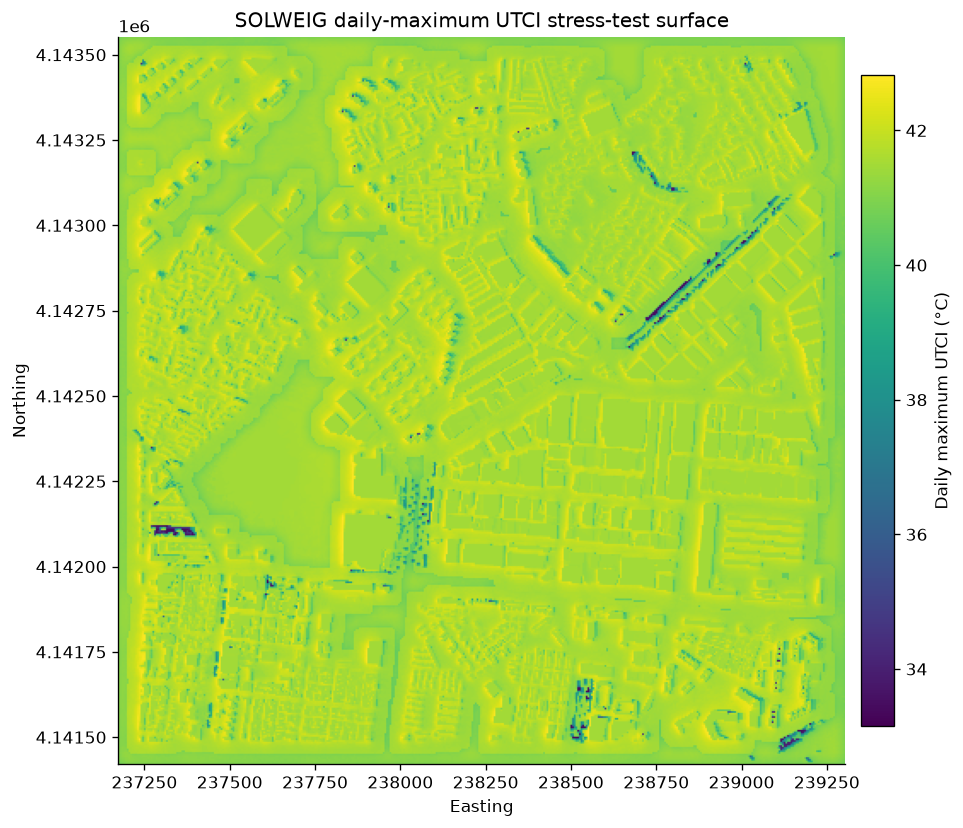

Raster mean: 41.51081685732549
Raster min: 33.15694808959961
Raster max: 42.816741943359375


In [4]:
utci_path = SOLWEIG_DIR / "utci_max.tif"

if utci_path.exists():
    with rasterio.open(utci_path) as src:
        utci = src.read(1, masked=True)
        extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(utci, extent=extent, origin="upper")
    cbar = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cbar.set_label("Daily maximum UTCI (°C)")
    ax.set_title("SOLWEIG daily-maximum UTCI stress-test surface")
    ax.set_xlabel("Easting")
    ax.set_ylabel("Northing")
    plt.tight_layout()
    plt.show()

    print("Raster mean:", float(utci.mean()))
    print("Raster min:", float(utci.min()))
    print("Raster max:", float(utci.max()))
else:
    print("UTCI raster not found:", utci_path)

### Early interpretation

The raster demonstrates that the urban-form pipeline can generate a spatial thermal field and connect it to the network analysis. However, using **cell-wise daily maximum UTCI** produces very severe conditions across much of the modeled area. This later turns out to be an important limitation because it reduces spatial contrast in thermal impedance.

## 5. Stage C — Thermalizing the walking network

The UTCI field was sampled onto walking-network edges. For the main PoC, each edge received:

- conventional walking time;
- UTCI;
- heat excess above 32°C;
- thermal walking cost;
- cost ratio \(c_e^{heat}/c_e\).

At \(\lambda=0.05\), the thermal cost ratio is expected to increase as modeled heat stress increases.

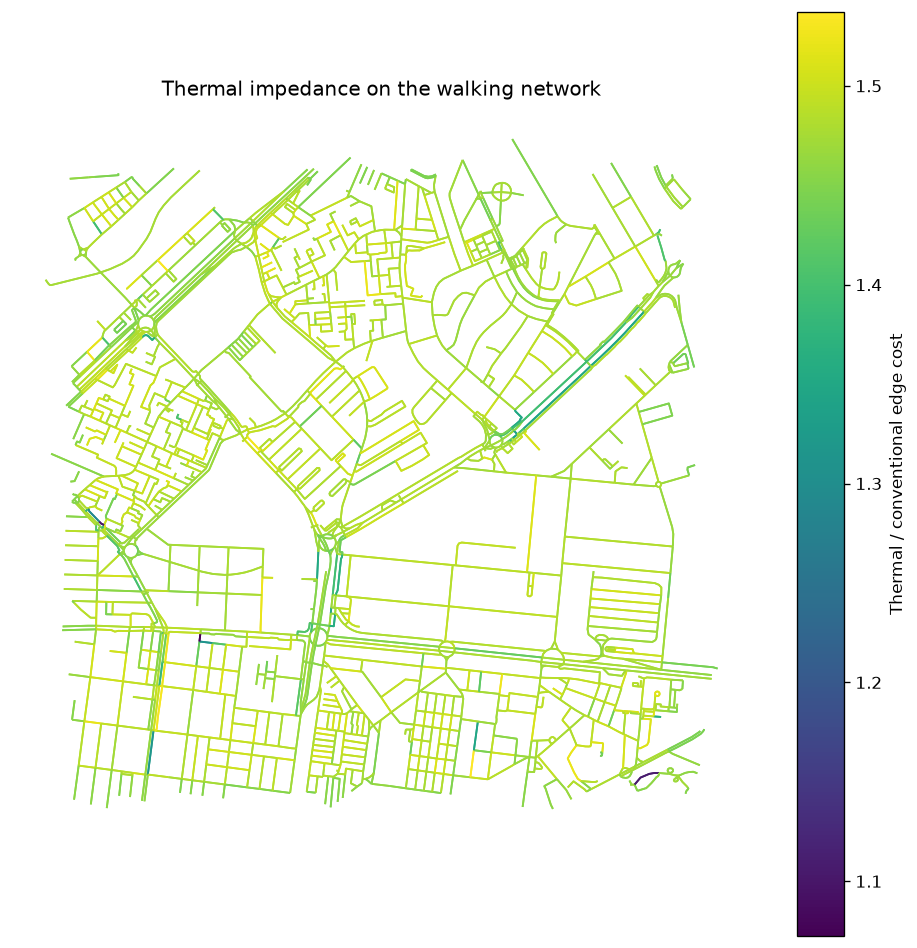

count    4470.000000
mean        1.476260
std         0.025785
min         1.072453
25%         1.468952
50%         1.478627
75%         1.488971
max         1.537133
Name: cost_ratio, dtype: float64


In [5]:
thermal_graph_path = INTERIM / "sevilla_walk_thermal.graphml"

if thermal_graph_path.exists():
    Gt = ox.load_graphml(thermal_graph_path)

    for _, _, _, data in Gt.edges(keys=True, data=True):
        for field in ["length","walk_time_s","utci_max","heat_excess",
                      "thermal_cost_s","cost_ratio"]:
            if field in data:
                try:
                    data[field] = float(data[field])
                except (TypeError, ValueError):
                    data[field] = np.nan

    _, thermal_edges = ox.graph_to_gdfs(Gt)

    valid = thermal_edges[
        thermal_edges["cost_ratio"].notna()
    ].copy()

    fig, ax = plt.subplots(figsize=(8, 8))
    valid.plot(
        ax=ax,
        column="cost_ratio",
        linewidth=1.1,
        legend=True,
        legend_kwds={"label": "Thermal / conventional edge cost"},
    )
    ax.set_title("Thermal impedance on the walking network")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

    ratio = valid["cost_ratio"].astype(float)
    print(ratio.describe())
else:
    print("Thermal graph not found:", thermal_graph_path)

### What the network diagnostic shows

For the final cleaned network, the mean cost ratio was approximately **1.477**, with a median of approximately **1.479**. Under the current PoC conditions, a 600-second thermal budget is therefore roughly equivalent to:

\[
600/1.477 \approx 406\text{ s} \approx 6.8\text{ min}
\]

of conventional walking cost.

This is a **model-specific PoC consequence**, not evidence of a universal 6.8-minute behavioral walking threshold.

## 6. Stage D — Route-level effects

The route experiment sampled 100 OD pairs. Thermal impedance changed the selected route for about **31%** of sampled pairs in the initial experiment, although thermal-cost reductions were usually small.

This figure summarizes route-selection outcomes from the saved route table.

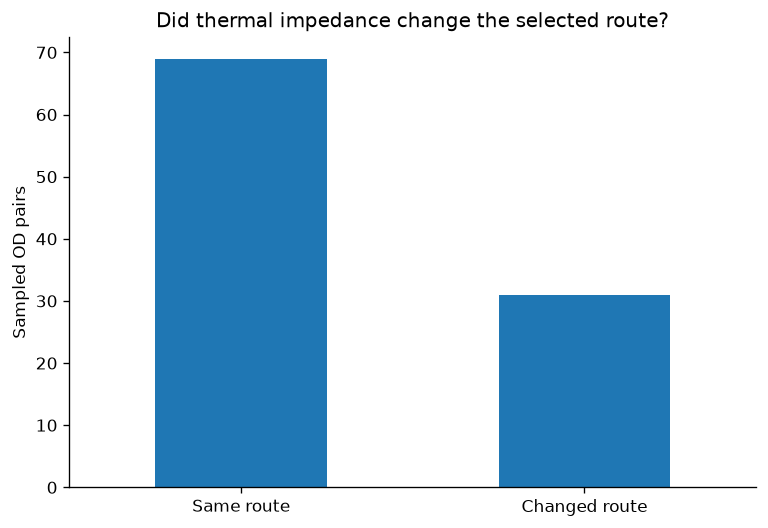

Changed-route share: 31.0%


In [6]:
routes_path = ACCESS_DIR / "route_results_lambda_005.csv"

if routes_path.exists():
    routes = pd.read_csv(routes_path)

    if "same_route" in routes.columns:
        same = routes["same_route"].astype(bool)
        route_summary = pd.Series({
            "Same route": int(same.sum()),
            "Changed route": int((~same).sum())
        })

        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        route_summary.plot(kind="bar", ax=ax)
        ax.set_ylabel("Sampled OD pairs")
        ax.set_title("Did thermal impedance change the selected route?")
        ax.tick_params(axis="x", rotation=0)
        plt.tight_layout()
        plt.show()

        print(f"Changed-route share: {(~same).mean()*100:.1f}%")
    else:
        print("Column 'same_route' not found.")
else:
    print("Route-results CSV not found:", routes_path)

### Early interpretation

Thermal impedance can affect **route choice**, but in this PoC the larger methodological effect appears in the fixed-budget accessibility analysis rather than in dramatic route diversions. The route result is therefore best read as evidence that the generalized-cost network behaves as intended.

## 7. Stage E — Heat-conditioned accessibility

Accessibility is measured as the number of transit-stop nodes reachable within a fixed **600-second generalized walking-cost budget**.

Two saved outputs summarize the main result:

1. origin-level normal versus thermal accessibility at \(\lambda=0.05\);
2. sensitivity of mean accessibility to alternative \(\lambda\) values.

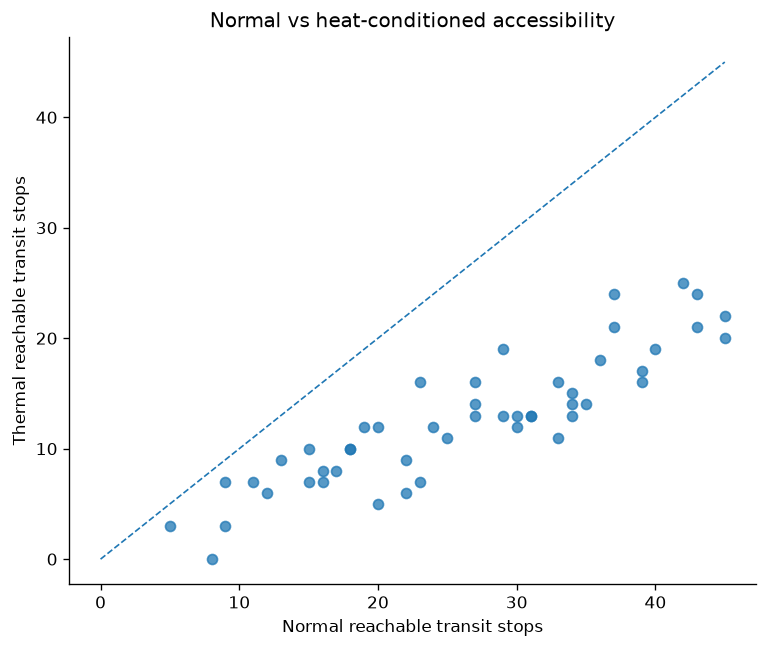

       normal_access  thermal_access  access_loss_pct
count      49.000000       49.000000        49.000000
mean       26.326531       12.673469        51.571989
std        10.859688        5.821611        13.384802
min         5.000000        0.000000        22.222222
25%        18.000000        8.000000        43.243243
50%        27.000000       13.000000        51.851852
75%        34.000000       16.000000        58.064516
max        45.000000       25.000000       100.000000


In [7]:
access_path = ACCESS_DIR / "origin_accessibility_lambda_005.csv"
sens_path = ACCESS_DIR / "accessibility_sensitivity.csv"

access = pd.read_csv(access_path) if access_path.exists() else None
sensitivity = pd.read_csv(sens_path) if sens_path.exists() else None

if access is not None:
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.scatter(access["normal_access"], access["thermal_access"], alpha=0.75)

    lim = max(access["normal_access"].max(), access["thermal_access"].max())
    ax.plot([0, lim], [0, lim], linestyle="--", linewidth=1)

    ax.set_xlabel("Normal reachable transit stops")
    ax.set_ylabel("Thermal reachable transit stops")
    ax.set_title("Normal vs heat-conditioned accessibility")
    plt.tight_layout()
    plt.show()

    print(access[["normal_access","thermal_access","access_loss_pct"]].describe())
else:
    print("Origin accessibility CSV not found.")

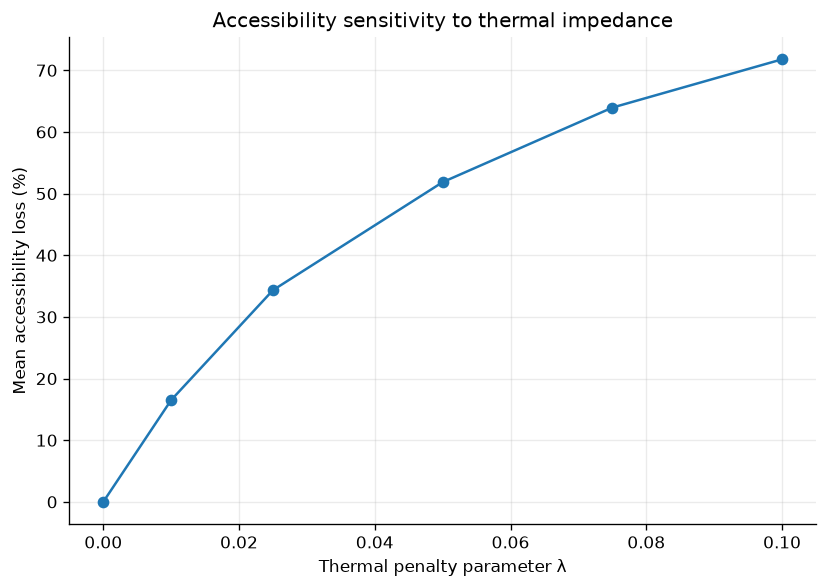

,lambda,mean,median,std,min,max,mean_access_loss_pct
0,0.000,26.326531,27.0,10.859688,5,45,0.000000
1,0.010,21.979592,22.0,9.967635,4,41,16.511628
2,0.025,17.285714,17.0,7.876653,0,36,34.341085
3,0.050,12.673469,13.0,5.821611,0,25,51.860465
4,0.075,9.489796,10.0,4.505194,0,20,63.953488
5,0.100,7.428571,7.0,3.937004,0,17,71.782946


In [8]:
if sensitivity is not None:
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(
        sensitivity["lambda"],
        sensitivity["mean_access_loss_pct"],
        marker="o"
    )
    ax.set_xlabel("Thermal penalty parameter λ")
    ax.set_ylabel("Mean accessibility loss (%)")
    ax.set_title("Accessibility sensitivity to thermal impedance")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    display(sensitivity)
else:
    print("Accessibility sensitivity CSV not found.")

### Early interpretation

Accessibility declines monotonically as the thermal penalty increases.

At \(\lambda=0.05\):

- mean normal accessibility ≈ **26.3 stops**;
- mean thermal accessibility ≈ **12.7 stops**;
- mean origin-level accessibility loss ≈ **51.6%**.

This is one of the clearest demonstrations that the computational method works. It should **not** be interpreted as a Sevilla-wide accessibility loss because the thermal simulation covers only the limited PoC area and \(\lambda\) is not behaviorally calibrated.

## 8. Stage F — Urban-form and thermal-accessibility diagnostics

Notebook 11 asked whether simple local urban-form conditions around each origin explain the modeled accessibility loss.

The 250 m buffer diagnostics produced weak direct correlations with accessibility loss, while tree density was more clearly associated with lower modeled local UTCI.

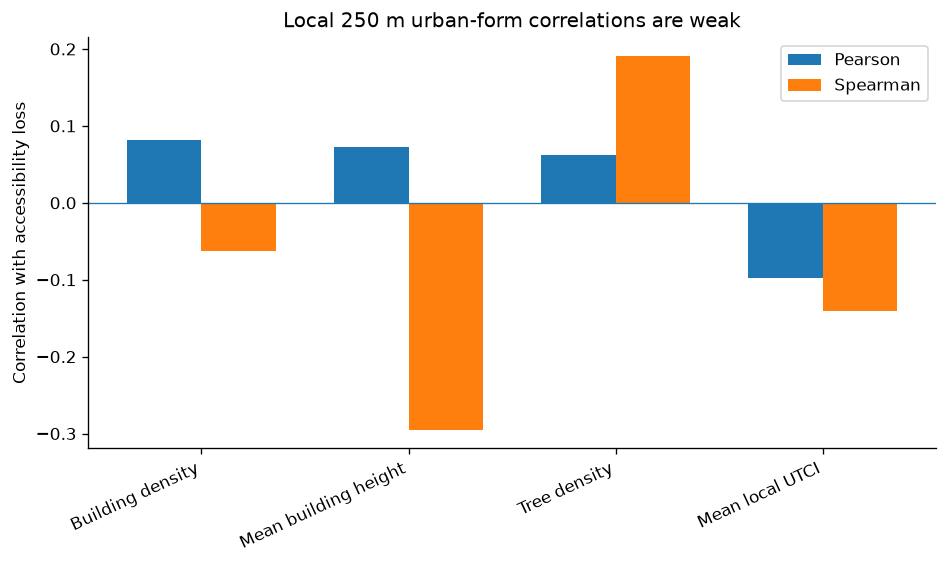

,Variable,Pearson,Spearman
0,Building density,0.082,-0.062
1,Mean building height,0.073,-0.295
2,Tree density,0.062,0.191
3,Mean local UTCI,-0.098,-0.140


In [9]:
urban_corr = pd.DataFrame({
    "Variable": [
        "Building density",
        "Mean building height",
        "Tree density",
        "Mean local UTCI",
    ],
    "Pearson": [
        0.082,
        0.073,
        0.062,
        -0.098,
    ],
    "Spearman": [
        -0.062,
        -0.295,
        0.191,
        -0.140,
    ],
})

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(urban_corr))
width = 0.36

ax.bar(x - width/2, urban_corr["Pearson"], width, label="Pearson")
ax.bar(x + width/2, urban_corr["Spearman"], width, label="Spearman")
ax.axhline(0, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(urban_corr["Variable"], rotation=25, ha="right")
ax.set_ylabel("Correlation with accessibility loss")
ax.set_title("Local 250 m urban-form correlations are weak")
ax.legend()
plt.tight_layout()
plt.show()

display(urban_corr)

### Early interpretation

The weak local-buffer relationships suggest that accessibility loss is not controlled by morphology immediately around the origin alone. This is conceptually reasonable: accessibility depends on thermal conditions distributed across the **reachable network**.

A more promising thermal diagnostic was the association between tree density and local modeled UTCI:

- Pearson ≈ **−0.47**
- Spearman ≈ **−0.59**

This supports the idea that urban form can structure thermal conditions even when its direct relationship with accessibility loss is weak.

## 9. Stage G — Reachable-network contraction

Notebook 11 then examined whether the thermalized network itself contracts under the fixed budget.

Across the 49 retained origins:

- mean conventional reachable nodes ≈ **333**;
- mean thermal reachable nodes ≈ **176**;
- mean reachable-node loss ≈ **46.9%**.

However, node contraction had only a weak relationship with accessibility loss:

- Pearson ≈ **0.252**
- Spearman ≈ **0.112**.

This shows why accessibility cannot be reduced to network-size loss alone: transit opportunities are not uniformly distributed across the network.

In [10]:
network_summary = pd.DataFrame({
    "Metric": [
        "Mean accessibility loss",
        "Mean reachable-node loss",
        "Pearson: node loss vs access loss",
        "Spearman: node loss vs access loss",
    ],
    "Value": [
        51.571989,
        46.890934,
        0.252,
        0.112,
    ],
    "Unit": ["%", "%", "r", "rho"],
})

display(network_summary)

,Metric,Value,Unit
0,Mean accessibility loss,51.571989,%
1,Mean reachable-node loss,46.890934,%
2,Pearson: node loss vs access loss,0.252000,r
3,Spearman: node loss vs access loss,0.112000,rho


## 10. Stage H — Opportunity-level mechanism

Notebook 12 reconstructed the exact 129 transit-stop nodes used in Notebook 07 and validated the accessibility calculation:

- normal counts matched exactly;
- thermal counts matched exactly;
- maximum discrepancy = **0**.

This allowed the model to be traced down to individual **origin–stop opportunities**.

In [11]:
opportunity_summary = pd.DataFrame({
    "Quantity": [
        "Normally reachable origin–stop opportunities",
        "Opportunities lost",
        "Overall loss rate",
        "Mean normal cost: retained opportunities",
        "Mean normal cost: lost opportunities",
        "Mean remaining margin: lost opportunities",
    ],
    "Value": [
        1290,
        669,
        51.9,
        262.117,
        513.497,
        86.503,
    ],
    "Unit": [
        "pairs",
        "pairs",
        "%",
        "s",
        "s",
        "s",
    ],
})

display(opportunity_summary)

,Quantity,Value,Unit
0,Normally reachable origin–stop opportunities,1290.000,pairs
1,Opportunities lost,669.000,pairs
2,Overall loss rate,51.900,%
3,Mean normal cost: retained opportunities,262.117,s
4,Mean normal cost: lost opportunities,513.497,s
5,Mean remaining margin: lost opportunities,86.503,s


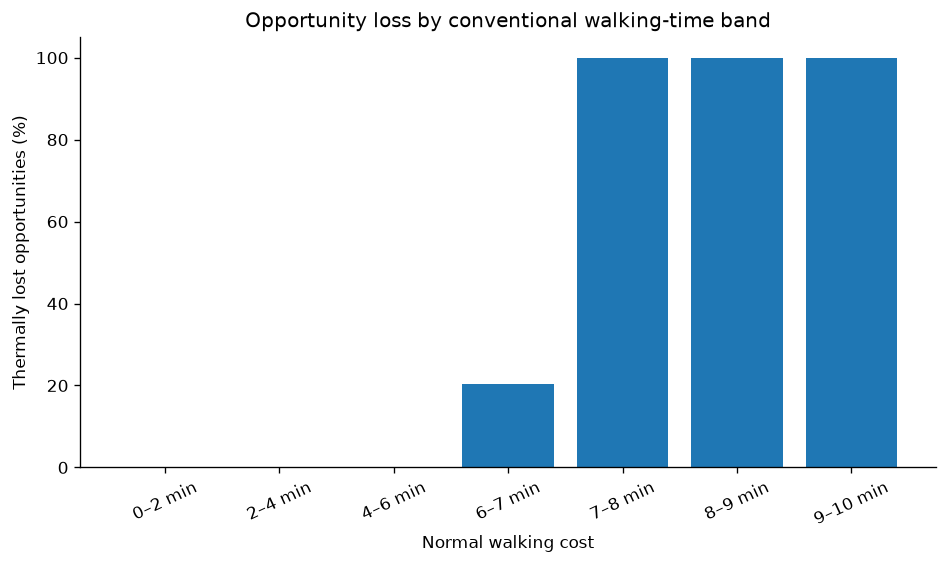

,Normal walking cost,Opportunities,Lost,Loss rate (%)
0,0–2 min,65,0,0.000000
1,2–4 min,186,0,0.000000
2,4–6 min,249,0,0.000000
3,6–7 min,152,31,20.394737
4,7–8 min,178,178,100.000000
5,8–9 min,212,212,100.000000
6,9–10 min,248,248,100.000000


In [12]:
bands = pd.DataFrame({
    "Normal walking cost": [
        "0–2 min", "2–4 min", "4–6 min",
        "6–7 min", "7–8 min", "8–9 min", "9–10 min"
    ],
    "Opportunities": [65, 186, 249, 152, 178, 212, 248],
    "Lost": [0, 0, 0, 31, 178, 212, 248],
})

bands["Loss rate (%)"] = 100 * bands["Lost"] / bands["Opportunities"]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(bands["Normal walking cost"], bands["Loss rate (%)"])
ax.set_xlabel("Normal walking cost")
ax.set_ylabel("Thermally lost opportunities (%)")
ax.set_title("Opportunity loss by conventional walking-time band")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

display(bands)

### Interpretation of the apparent 6–7 minute breakpoint

The sharp transition is mainly a **mechanical consequence of the current cost surface**.

The final network had:

- mean thermal cost ratio ≈ **1.4767**;
- median ≈ **1.4789**;
- effective conventional-time equivalent of a 600 s thermal budget ≈ **406 s = 6.77 min**.

Therefore, the opportunity-loss curve validates the internal model mechanism, but it does **not** reveal a universal thermal walking threshold.

## 11. Stage I — Observed mobility response

Spanish mobile-phone OD data provide an independent observational layer.

For the selected hot and reference weekdays, the descriptive comparison showed:

- mean matched-day mobility change ≈ **−15.7%**;
- morning (06–11) ≈ **−10.9%**;
- afternoon (12–18) ≈ **−18.3%**;
- evening (19–23) ≈ **−17.1%**.

These results are descriptive rather than causal.

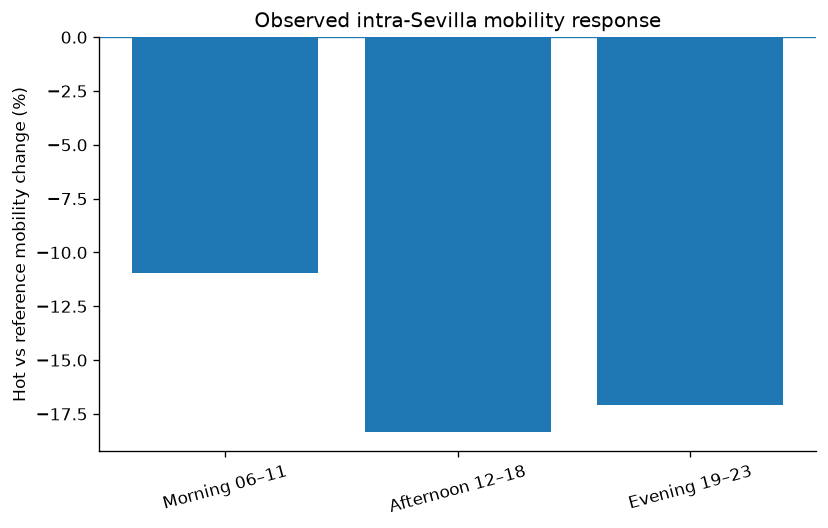

,Period,Mobility change (%)
0,Morning 06–11,-10.948619
1,Afternoon 12–18,-18.326436
2,Evening 19–23,-17.071757


In [13]:
period_changes = pd.DataFrame({
    "Period": ["Morning 06–11", "Afternoon 12–18", "Evening 19–23"],
    "Mobility change (%)": [-10.948619, -18.326436, -17.071757],
})

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(period_changes["Period"], period_changes["Mobility change (%)"])
ax.axhline(0, linewidth=0.8)
ax.set_ylabel("Hot vs reference mobility change (%)")
ax.set_title("Observed intra-Sevilla mobility response")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

display(period_changes)

### Spatial-scale warning

The mobile-phone analysis covers **all 11 Sevilla districts**, while the current thermal-accessibility PoC covers only a small part of the city. The 49 modeled origins are concentrated in only three districts.

For that reason, the current modeled accessibility loss and the observed −15.7% mobility change should **not** be treated as directly comparable citywide effects.

At this stage, the mobile analysis demonstrates that a plausible observational validation layer exists for a future expanded thermal model.

## 12. What the proof-of-concept demonstrates

Taken together, the notebooks establish the following chain:

1. Urban-form data can be prepared for microclimate simulation.
2. SOLWEIG can produce a spatial thermal field for the study area.
3. Thermal conditions can be transferred onto pedestrian-network edges.
4. Thermal stress can be incorporated directly into generalized walking cost.
5. The modified cost can change selected routes.
6. The thermalized network contracts under a fixed generalized-cost budget.
7. Reachable transit opportunities decline systematically as the thermal penalty increases.
8. Accessibility loss can be traced to specific origin–stop opportunities.
9. Local urban-form metrics alone do not explain the accessibility effect well, pointing toward network-scale thermal context.
10. Mobile-phone OD data provide a promising independent behavioral layer for later validation.

**This is a successful methodological proof-of-concept.**

## 13. What the proof-of-concept also revealed

A good PoC should expose limitations as well as demonstrate feasibility.

### Thermal representation
The daily-maximum UTCI surface is too severe and spatially homogeneous for a strong explanatory analysis. Most of the reachable network is above the chosen stress thresholds, so edge-cost ratios cluster near ~1.48.

### Spatial extent
The thermal simulation covers only a small area of Sevilla, while the mobile data cover all 11 districts.

### Behavioral interpretation
The parameter \(\lambda\) is a sensitivity parameter. It has not yet been calibrated against observed walking behavior.

### Opportunity measure
Accessibility currently counts reachable transit-stop nodes. A later study could incorporate service frequency, destination importance, or other opportunity weights.

These limitations do not invalidate the method; they identify the next methodological refinements.

## 14. Next methodological stage

The next-stage experiment should move from a small stress-test PoC toward a spatially representative Sevilla analysis:

\[
\text{urban form}
\rightarrow
\text{common-hour UTCI}
\rightarrow
\text{heterogeneous thermal edge costs}
\rightarrow
\text{accessibility loss}
\rightarrow
\text{district-level mobility response}
\]

Priority changes:

1. **Expand the thermal domain** to represent a meaningful portion of Sevilla, ideally enough to support district-level comparison.
2. Replace cell-wise daily maximum UTCI with **common hot-afternoon snapshots** such as 14:00, 15:00, and 16:00.
3. Use stronger urban-form measures such as canopy/shade fraction, street enclosure, or network-weighted morphology.
4. Aggregate modeled accessibility effects to spatial units compatible with the mobile OD data.
5. Treat calibration of \(\lambda\) as a later empirical step rather than assuming the PoC value is behavioral.

## 15. Proof-of-concept takeaway

The project demonstrates that environmental stress can be embedded **inside accessibility impedance**, rather than treated only as an external exposure variable.

The current evidence supports the computational feasibility and internal consistency of this approach. At the same time, the PoC clearly identifies the two refinements needed before citywide interpretation:

- a broader spatial model;
- a more informative common-hour thermal representation.

That combination provides a defensible bridge from the present proof-of-concept to a publishable city-scale experiment.